In [10]:
%load_ext autoreload
%autoreload 2
import sys
from sc_foi.bbq.bbq_circuit_fitting import BlackBoxAdmittanceModel, TwoCavityOneCouplerModel

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import numpy as np
from lmfit import create_params

# Fitting two modes

In [12]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_two = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate.csv",
                                ljs=ljs, n_modes=2)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for STIXGeneral, now using 400.
findfont: Failed to find font weight medium for STIXGeneral, now using 400.
findfont: Failed to find font weight medium for STIXNonUnicode, now using 400.
findfont: Failed to find font weight medium for STIXNonUnicode, now using 400.
findfont: Failed to find font weight medium for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight medium for cmmi10, now usi

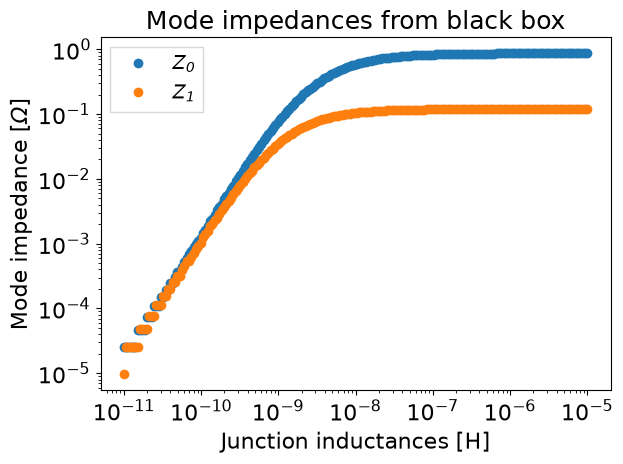

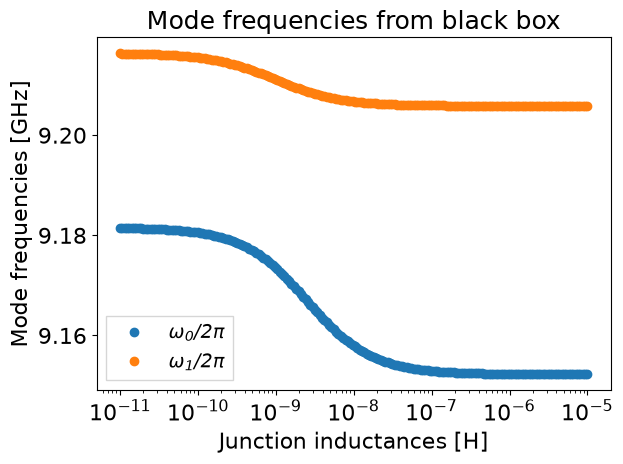

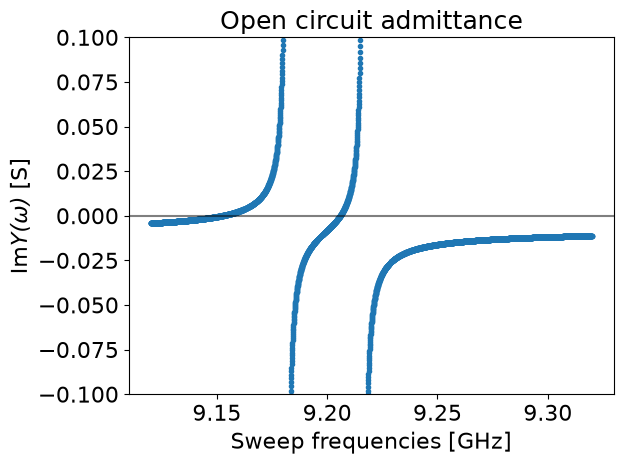

In [13]:
bbq_am_two.run()

# Fitting three modes

In [14]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_three = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate_with_coupler.csv",
                                ljs=ljs, n_modes=3)

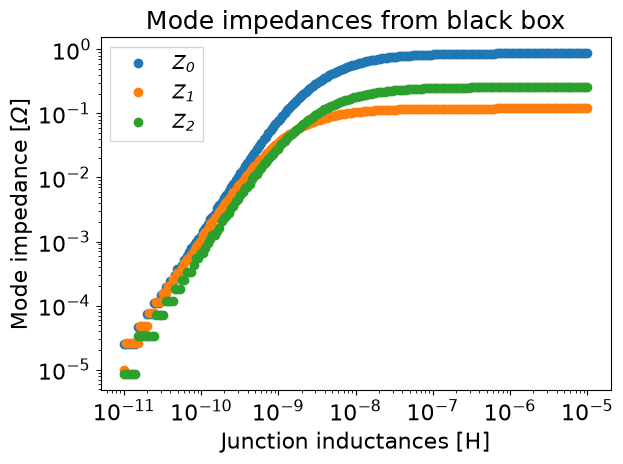

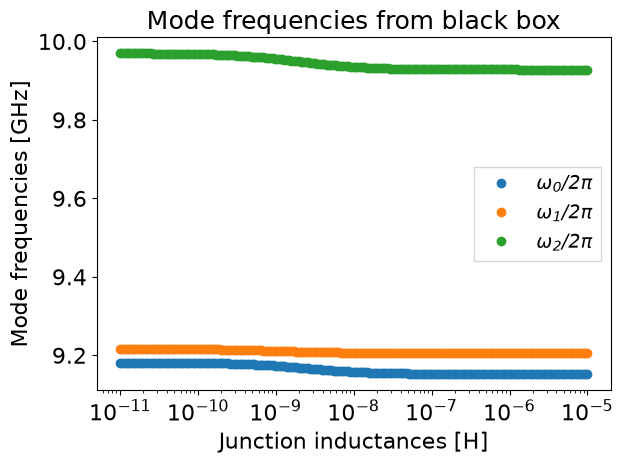

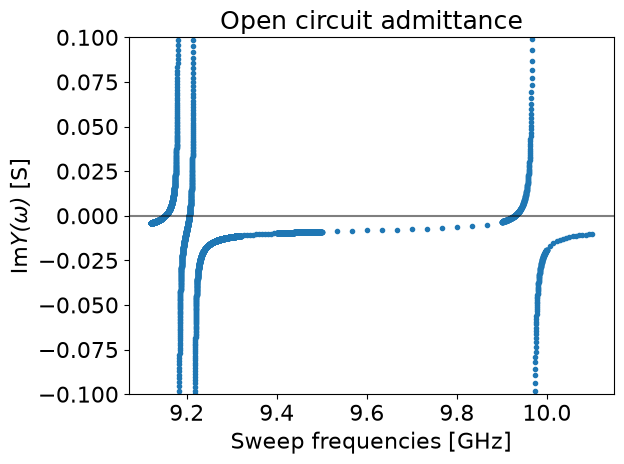

In [15]:
bbq_am_three.run()

## Fit the mode impedances

In [16]:
mode_index = 0
unit_scale = 1e9
zp = bbq_am_three.mode_impedances[:, mode_index]
zps = bbq_am_three.mode_impedances
wps = bbq_am_three.mode_frequencies * unit_scale
circ_model = TwoCavityOneCouplerModel(data=zps, x=ljs * unit_scale, unit_scale=unit_scale)

In [17]:
fit_result = circ_model.minimize() # method="differential_evolution")

In [ ]:
fit_result.params

In [ ]:
circ_model.plot_fit(params=fit_result.params)

In [ ]:
params = circ_model.guess(zp, x=ljs * unit_scale)
fit_result = circ_model.fit(zp, x=ljs * unit_scale, params=params, )

In [ ]:
fit_result.params

In [ ]:
fit_result.plot_fit()